# Práctica 1 – Clasificación de estilos artísticos con redes convolucionales

**Aprendizaje Automático II · 2026-27**

Clasificador de imágenes de cuadros en **7 estilos artísticos** (*Baroque, Cubism, Impressionism, Minimalism, Pointillism, Medieval, Ukiyo-e*) con 300 imágenes por clase (2100 en total), implementado en PyTorch con redes convolucionales, *pooling*, *dropout*, *batch normalization* y parada anticipada.

## 1. Entorno

In [ ]:
try:
    from google.colab import drive
    IN_COLAB = True
except:
    IN_COLAB = False

In [ ]:
import os
import copy
import random
from time import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import transforms, models
from torchvision.datasets import ImageFolder

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

Se fija una semilla para que la inicialización de los pesos, el orden de los lotes y la partición de los datos sean reproducibles entre configuraciones. Esto ayuda a reducir la variabilidad entre experimentos.

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Usando dispositivo: {device}')

SEMILLA = 42
NUM_WORKERS = 2


def fijar_semilla(semilla=SEMILLA):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)


fijar_semilla()

Usando dispositivo: cuda


## 2. Datos

### 2.1 Carga y copia local

El *dataset* está en Google Drive con una subcarpeta por clase. Leer las imágenes directamente desde Drive en cada época es muy lento y muchas de ellas tienen varios megapíxeles, así que antes de entrenar se hace una única copia local en `/content`.

In [ ]:
if IN_COLAB:
    drive.mount('/content/drive')
    raiz_AA2 = '/content/drive/MyDrive/PROYECTO AA2'
    ruta_local = '/content/dataset_256'
else:
    raiz_AA2 = '.'
    ruta_local = 'dataset_256'

ruta_dataset_original = os.path.join(raiz_AA2, 'dataset')

Mounted at /content/drive


In [ ]:
LADO_MINIMO = 256


def copiar_redimensionado(origen, destino, lado_minimo=LADO_MINIMO):
    for clase in sorted(os.listdir(origen)):
        carpeta_origen = os.path.join(origen, clase)
        if clase.startswith('.') or not os.path.isdir(carpeta_origen):
            continue
        carpeta_destino = os.path.join(destino, clase)
        os.makedirs(carpeta_destino, exist_ok=True)
        for fichero in sorted(os.listdir(carpeta_origen)):
            nombre_destino = fichero if fichero.lower().endswith(('.jpg', '.jpeg')) else fichero + '.jpg'
            ruta_destino = os.path.join(carpeta_destino, nombre_destino)
            if os.path.exists(ruta_destino):
                continue
            try:
                with Image.open(os.path.join(carpeta_origen, fichero)) as img:
                    img = img.convert('RGB')
                    escala = lado_minimo / min(img.size)
                    if escala < 1:
                        img = img.resize((round(img.width * escala), round(img.height * escala)), Image.BICUBIC)
                    img.save(ruta_destino, 'JPEG', quality=95)
            except OSError:
                print(f'Imagen descartada: {os.path.join(clase, fichero)}')


inicio = time()
copiar_redimensionado(ruta_dataset_original, ruta_local)
print(f'Copia local preparada en {time() - inicio:.1f} s')

Copia local preparada en 357.8 s


In [ ]:
dataset = ImageFolder(root=ruta_local)
clases = dataset.classes
num_clases = len(clases)
etiquetas_dataset = np.array(dataset.targets)

print('Número de imágenes:', len(dataset))
print('Etiquetas:', dataset.class_to_idx)

Número de imágenes: 2100
Etiquetas: {'Baroque': 0, 'Cubism': 1, 'Impressionism': 2, 'Medieval': 3, 'Minimalism': 4, 'Pointillism': 5, 'Ukiyo': 6}


### 2.2 Partición entrenamiento / validación / test

División **estratificada 70/15/15** (1470/315/315 imágenes), manteniendo la proporción de clases:

- **Entrenamiento:** ajuste de los pesos.
- **Validación:** parada anticipada y selección de hiperparámetros.
- **Test:** evaluación final de los modelos seleccionados.

In [ ]:
indices = np.arange(len(dataset))

indices_train, indices_temp = train_test_split(
    indices, test_size=0.30, stratify=etiquetas_dataset, random_state=SEMILLA
)
indices_val, indices_test = train_test_split(
    indices_temp, test_size=0.50, stratify=etiquetas_dataset[indices_temp], random_state=SEMILLA
)

print('Entrenamiento:', len(indices_train))
print('Validación:', len(indices_val))
print('Test:', len(indices_test))


Entrenamiento: 1470
Validación: 315
Test: 315


### 2.3 Transformaciones y aumento de datos

- **Tamaño de entrada:** 128×128 para las CNN propias y 224×224 para ResNet-50.
- **Normalización:** utilizando la media y desviación típica de ImageNet.
- **Aumento de datos:** aplicado únicamente en entrenamiento, mediante recortes aleatorios, volteo horizontal, rotaciones de ±10° y pequeñas variaciones de brillo, contraste y saturación.

In [ ]:
MEDIA = [0.485, 0.456, 0.406]
DESVIACION = [0.229, 0.224, 0.225]
TAM_CNN = 128
TAM_PREENTRENADO = 224


def crear_transformaciones(tam, aumento=False):
    if aumento:
        pasos = [
            transforms.RandomResizedCrop(tam, scale=(0.6, 1.0), ratio=(0.8, 1.25)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(10),
            transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1)
        ]
    else:
        pasos = [transforms.Resize((tam, tam))]
    return transforms.Compose(pasos + [transforms.ToTensor(), transforms.Normalize(MEDIA, DESVIACION)])


def crear_loaders(batch_size, tam, aumento=False):
    dataset_train = Subset(ImageFolder(ruta_local, transform=crear_transformaciones(tam, aumento)), indices_train)
    dataset_eval = ImageFolder(ruta_local, transform=crear_transformaciones(tam))
    opciones = dict(num_workers=NUM_WORKERS, pin_memory=device == 'cuda', persistent_workers=NUM_WORKERS > 0)
    loader_train = DataLoader(dataset_train, batch_size=batch_size, shuffle=True,
                              generator=torch.Generator().manual_seed(SEMILLA), **opciones)
    loader_val = DataLoader(Subset(dataset_eval, indices_val), batch_size=batch_size, shuffle=False, **opciones)
    loader_test = DataLoader(Subset(dataset_eval, indices_test), batch_size=batch_size, shuffle=False, **opciones)
    return loader_train, loader_val, loader_test

### 2.4 Visualización

Dos ejemplos de cada clase del conjunto de entrenamiento y el efecto del aumento de datos sobre una misma imagen (cada acceso aplica transformaciones aleatorias distintas).

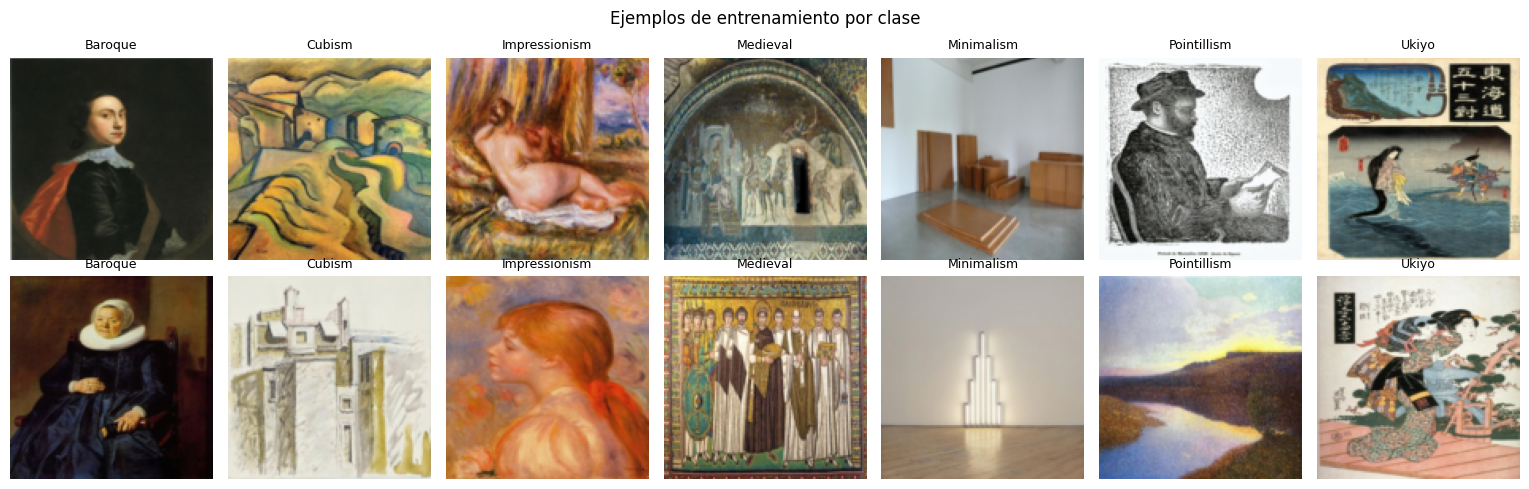

In [ ]:
def desnormalizar(imagen):
    media = torch.tensor(MEDIA).view(3, 1, 1)
    desviacion = torch.tensor(DESVIACION).view(3, 1, 1)
    return (imagen * desviacion + media).clamp(0, 1).permute(1, 2, 0).numpy()


def mostrar_imagenes(imagenes, titulos, titulo_figura, columnas=7):
    filas = int(np.ceil(len(imagenes) / columnas))
    _, ejes = plt.subplots(filas, columnas, figsize=(2.2 * columnas, 2.5 * filas), squeeze=False)
    for eje in ejes.flatten():
        eje.axis('off')
    for eje, imagen, titulo in zip(ejes.flatten(), imagenes, titulos):
        eje.imshow(desnormalizar(imagen))
        eje.set_title(titulo, fontsize=9)
    plt.suptitle(titulo_figura)
    plt.tight_layout()
    plt.show()


dataset_visual = ImageFolder(ruta_local, transform=crear_transformaciones(TAM_CNN))
ejemplos = [indices_train[etiquetas_dataset[indices_train] == c][i] for i in range(2) for c in range(num_clases)]
mostrar_imagenes([dataset_visual[i][0] for i in ejemplos],
                 [clases[etiquetas_dataset[i]] for i in ejemplos],
                 'Ejemplos de entrenamiento por clase')

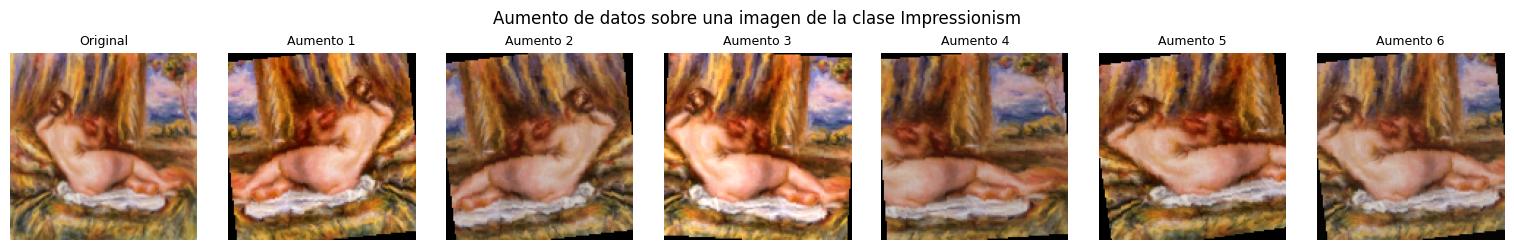

In [ ]:
dataset_aumentado = ImageFolder(ruta_local, transform=crear_transformaciones(TAM_CNN, aumento=True))
indice = indices_train[0]
mostrar_imagenes([dataset_visual[indice][0]] + [dataset_aumentado[indice][0] for _ in range(6)],
                 ['Original'] + [f'Aumento {i + 1}' for i in range(6)],
                 f'Aumento de datos sobre una imagen de la clase {clases[etiquetas_dataset[indice]]}')

## 3. Entrenamiento, evaluación y parada anticipada

Se utilizan funciones reutilizables para evitar repetir código en cada configuración:

- **`evaluar`:** calcula la pérdida, el *accuracy* y las predicciones sin calcular gradientes.
- **`entrenar`:** ejecuta el entrenamiento y registra las métricas de entrenamiento y validación en cada época.


Se utiliza el optimizador Adam.

In [ ]:
def evaluar(modelo, loader, criterio=nn.CrossEntropyLoss()):
    modelo.eval()
    perdida_total = 0.0
    y_real, y_pred = [], []
    with torch.no_grad():
        for imagenes, etiquetas in loader:
            imagenes, etiquetas = imagenes.to(device), etiquetas.to(device)
            salidas = modelo(imagenes)
            perdida_total += criterio(salidas, etiquetas).item() * etiquetas.size(0)
            y_pred.append(salidas.argmax(dim=1).cpu().numpy())
            y_real.append(etiquetas.cpu().numpy())
    y_real, y_pred = np.concatenate(y_real), np.concatenate(y_pred)
    return perdida_total / len(y_real), accuracy_score(y_real, y_pred), y_real, y_pred


def entrenar(modelo, loader_train, loader_val, lr, epocas, paciencia, scheduler=False):
    criterio = nn.CrossEntropyLoss()
    opt = optim.Adam([p for p in modelo.parameters() if p.requires_grad], lr=lr)
    planificador = optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=2) if scheduler else None

    historial = {'perdida_train': [], 'perdida_val': [], 'acc_train': [], 'acc_val': []}
    mejor_perdida, mejor_epoca, mejor_estado, epocas_sin_mejora = float('inf'), 0, None, 0

    for epoca in range(epocas):
        modelo.train()
        perdida_total, aciertos, total = 0.0, 0, 0
        for imagenes, etiquetas in loader_train:
            imagenes, etiquetas = imagenes.to(device), etiquetas.to(device)
            opt.zero_grad()
            salidas = modelo(imagenes)
            perdida = criterio(salidas, etiquetas)
            perdida.backward()
            opt.step()
            perdida_total += perdida.item() * etiquetas.size(0)
            aciertos += (salidas.argmax(dim=1) == etiquetas).sum().item()
            total += etiquetas.size(0)

        perdida_val, acc_val, _, _ = evaluar(modelo, loader_val, criterio)
        historial['perdida_train'].append(perdida_total / total)
        historial['acc_train'].append(aciertos / total)
        historial['perdida_val'].append(perdida_val)
        historial['acc_val'].append(acc_val)

        if planificador:
            planificador.step(perdida_val)

        mejora = perdida_val < mejor_perdida
        if mejora:
            mejor_perdida, mejor_epoca, epocas_sin_mejora = perdida_val, epoca + 1, 0
            mejor_estado = copy.deepcopy(modelo.state_dict())
        else:
            epocas_sin_mejora += 1

        print(f'Época [{epoca + 1:2d}/{epocas}] | '
              f'Train Loss: {historial["perdida_train"][-1]:.4f} | Train Acc: {historial["acc_train"][-1]:.4f} | '
              f'Val Loss: {perdida_val:.4f} | Val Acc: {acc_val:.4f}'
              + ('  -> mejora' if mejora else f'  -> sin mejora ({epocas_sin_mejora}/{paciencia})'))

        if epocas_sin_mejora >= paciencia:
            print(f'Parada anticipada en la época {epoca + 1}: la mejor fue la {mejor_epoca} '
                  f'(Val Loss: {mejor_perdida:.4f})')
            break

    modelo.load_state_dict(mejor_estado)
    historial['mejor_epoca'] = mejor_epoca
    return historial

Funciones auxiliares para visualizar las **curvas de pérdida y precisión**, marcar la mejor época y registrar los resultados de cada configuración en una tabla comparativa.

In [ ]:
def graficar_historial(historial, titulo):
    separaciones = historial.get('separaciones', ())
    epocas_eje = range(1, len(historial['perdida_train']) + 1)
    _, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
    for eje, clave, nombre in zip(ejes, ['perdida', 'acc'], ['Pérdida', 'Precisión (accuracy)']):
        eje.plot(epocas_eje, historial[f'{clave}_train'], marker='.', label='Entrenamiento')
        eje.plot(epocas_eje, historial[f'{clave}_val'], marker='.', label='Validación')
        eje.axvline(historial['mejor_epoca'], color='red', linestyle='--',
                    label=f'Mejor época ({historial["mejor_epoca"]})')
        for separacion in separaciones:
            eje.axvline(separacion + 0.5, color='gray', linestyle=':', label='Inicio del ajuste fino')
        eje.set_xlabel('Época')
        eje.set_ylabel(nombre)
        eje.set_title(f'Evolución de la {nombre.split()[0].lower()}')
        eje.grid(True, alpha=0.3)
        eje.legend()
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()


resultados = []
modelos = {}


def registrar(nombre, tipo, parametros, modelo, historial, tam, batch_size, duracion):
    i = historial['mejor_epoca'] - 1
    resultados[:] = [r for r in resultados if r['Configuración'] != nombre]
    resultados.append({
        'Configuración': nombre,
        'Tipo': tipo,
        **parametros,
        'Épocas entrenadas': len(historial['perdida_train']),
        'Mejor época': historial['mejor_epoca'],
        'Pérdida val': round(historial['perdida_val'][i], 4),
        'Acc train (%)': round(100 * historial['acc_train'][i], 2),
        'Acc val (%)': round(100 * historial['acc_val'][i], 2),
        'Tiempo (s)': round(duracion, 1)
    })
    modelos[nombre] = {'modelo': modelo.cpu(), 'historial': historial, 'tam': tam, 'batch_size': batch_size}
    print(f'{nombre}: mejor época {historial["mejor_epoca"]} | pérdida val {historial["perdida_val"][i]:.4f} | '
          f'accuracy val {100 * historial["acc_val"][i]:.2f}% | {duracion:.0f} s')

## 4. Red convolucional configurable

Se define una única clase CNN que permite probar distintas arquitecturas modificando sus parámetros:

- **`filtros` y `kernel`:** número de capas convolucionales y de filtros de cada una, y tamaño de los kernels.
- **`neuronas`:** capas densas y número de neuronas.
- **`activacion`:** ReLU o LeakyReLU.
- **`dropout`:** probabilidad de *dropout* tras cada capa densa.
- **`batch_norm`:** activa la normalización por lotes.
- **`pooling_global`:** permite utilizar *global average pooling* en lugar de aplanar las características.

Cada bloque convolucional incluye convolución, activación y *max pooling*, con BatchNorm opcional.

La configuración por defecto corresponde a la red inicial adaptada a 128×128 y 7 clases.

In [ ]:
ACTIVACIONES = {
    'relu': nn.ReLU,
    'leaky_relu': lambda: nn.LeakyReLU(0.1)
}


class CNN(nn.Module):
    def __init__(self, filtros=(16, 32, 64), kernel=5, neuronas=(128,), activacion='relu', dropout=0.25,
                 batch_norm=False, pooling_global=False, num_clases=num_clases, tam_imagen=TAM_CNN):
        super().__init__()
        capas = []
        canales = 3
        for f in filtros:
            capas.append(nn.Conv2d(canales, f, kernel_size=kernel, stride=1, padding=kernel // 2))
            if batch_norm:
                capas.append(nn.BatchNorm2d(f))
            capas += [ACTIVACIONES[activacion](), nn.MaxPool2d(kernel_size=2, stride=2)]
            canales = f
        self.extractor = nn.Sequential(*capas)

        if pooling_global:
            capas_fc = [nn.AdaptiveAvgPool2d(1), nn.Flatten()]
            entradas = canales
        else:
            lado = tam_imagen // 2 ** len(filtros)
            capas_fc = [nn.Flatten()]
            entradas = canales * lado * lado
        for n in neuronas:
            capas_fc += [nn.Linear(entradas, n), ACTIVACIONES[activacion](), nn.Dropout(dropout)]
            entradas = n
        capas_fc.append(nn.Linear(entradas, num_clases))
        self.clasificador = nn.Sequential(*capas_fc)

    def forward(self, x):
        return self.clasificador(self.extractor(x))


def contar_parametros(modelo, solo_entrenables=True):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad or not solo_entrenables)


modelo_base = CNN()
print(modelo_base)
print(f'Parámetros: {contar_parametros(modelo_base):,}')
print('Salida para un lote de 2 imágenes:', modelo_base(torch.zeros(2, 3, TAM_CNN, TAM_CNN)).shape)

CNN(
  (extractor): Sequential(
    (0): Conv2d(3, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (clasificador): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=7, bias=True)
  )
)
Parámetros: 2,163,495
Salida para un lote de 2 imágenes: torch.Size([2, 7])


Cada configuración se describe con un diccionario que reúne los hiperparámetros de arquitectura y de entrenamiento. `ejecutar_configuracion` crea los *loaders* y el modelo, entrena con parada anticipada, dibuja las curvas y registra el resultado.

In [ ]:
CLAVES_ARQUITECTURA = ('filtros', 'kernel', 'neuronas', 'activacion', 'dropout', 'batch_norm', 'pooling_global')


def describir(cfg):
    return {
        'Arquitectura': f"CNN {len(cfg['filtros'])} conv + {len(cfg['neuronas'])} FC",
        'Filtros': '-'.join(map(str, cfg['filtros'])),
        'Kernel': cfg['kernel'],
        'Neuronas FC': '-'.join(map(str, cfg['neuronas'])),
        'Activación': cfg['activacion'],
        'Dropout': cfg['dropout'],
        'BatchNorm': cfg['batch_norm'],
        'GAP': cfg['pooling_global'],
        'Aumento': cfg['aumento'],
        'LR': cfg['lr'],
        'Batch': cfg['batch_size'],
        'Épocas máx.': cfg['epocas'],
        'Paciencia': cfg['paciencia']
    }


def construir_y_entrenar(cfg):
    fijar_semilla()
    loader_train, loader_val, _ = crear_loaders(cfg['batch_size'], TAM_CNN, cfg['aumento'])
    modelo = CNN(**{clave: cfg[clave] for clave in CLAVES_ARQUITECTURA}).to(device)
    print(f'Parámetros entrenables: {contar_parametros(modelo):,}')
    inicio = time()
    historial = entrenar(modelo, loader_train, loader_val, lr=cfg['lr'], epocas=cfg['epocas'],
                         paciencia=cfg['paciencia'], scheduler=cfg['scheduler'])
    return modelo, historial, time() - inicio


def ejecutar_configuracion(nombre, cfg, tipo='Manual'):
    modelo, historial, duracion = construir_y_entrenar(cfg)
    registrar(nombre, tipo, describir(cfg), modelo, historial, TAM_CNN, cfg['batch_size'], duracion)
    graficar_historial(historial, f'{nombre} – {describir(cfg)["Arquitectura"]}, lr={cfg["lr"]}, batch={cfg["batch_size"]}')

## 5. Búsqueda manual de hiperparámetros

Se prueban **10 configuraciones**, modificando distintos hiperparámetros a partir de la red base. Todas utilizan la misma partición de datos, semilla y parada anticipada.

La comparación se realiza mediante el **conjunto de validación**, reservando el de test para la evaluación final.

Los hiperparámetros explorados incluyen la tasa de aprendizaje, tamaño de lote, *dropout*, arquitectura de la red, función de activación, *batch normalization*, *global average pooling* y aumento de datos.

### C1 – Configuración base

Red de 3 capas convolucionales (16, 32 y 64 filtros de 5×5), una capa densa de 128 neuronas, ReLU, *dropout* 0.25, Adam con `lr = 0.001` y lotes de 32 imágenes. Es el punto de referencia.

Parámetros entrenables: 2,163,495
Época [ 1/40] | Train Loss: 1.8024 | Train Acc: 0.2823 | Val Loss: 1.7720 | Val Acc: 0.2857  -> mejora
Época [ 2/40] | Train Loss: 1.6959 | Train Acc: 0.3707 | Val Loss: 1.5997 | Val Acc: 0.4095  -> mejora
Época [ 3/40] | Train Loss: 1.5372 | Train Acc: 0.4429 | Val Loss: 1.4177 | Val Acc: 0.4762  -> mejora
Época [ 4/40] | Train Loss: 1.3967 | Train Acc: 0.4769 | Val Loss: 1.4055 | Val Acc: 0.5111  -> mejora
Época [ 5/40] | Train Loss: 1.2543 | Train Acc: 0.5463 | Val Loss: 1.3983 | Val Acc: 0.4889  -> mejora
Época [ 6/40] | Train Loss: 1.1388 | Train Acc: 0.5844 | Val Loss: 1.3742 | Val Acc: 0.4794  -> mejora
Época [ 7/40] | Train Loss: 1.0048 | Train Acc: 0.6367 | Val Loss: 1.4151 | Val Acc: 0.5111  -> sin mejora (1/6)
Época [ 8/40] | Train Loss: 0.9204 | Train Acc: 0.6748 | Val Loss: 1.4946 | Val Acc: 0.4857  -> sin mejora (2/6)
Época [ 9/40] | Train Loss: 0.7109 | Train Acc: 0.7476 | Val Loss: 1.5699 | Val Acc: 0.5206  -> sin mejora (3/6)
Época [10

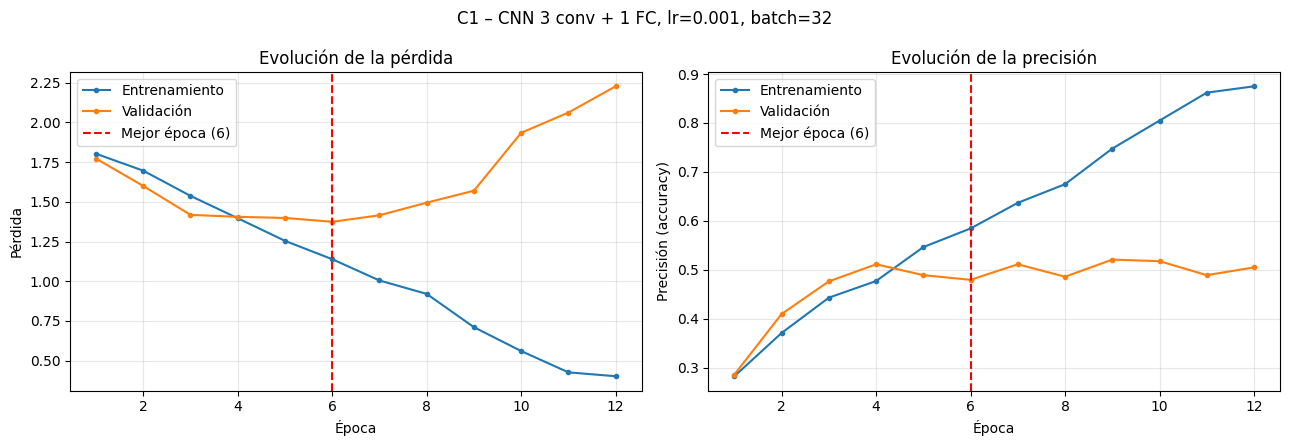

In [ ]:
C1 = dict(
    filtros=(16, 32, 64), kernel=5, neuronas=(128,), activacion='relu', dropout=0.25,
    batch_norm=False, pooling_global=False,
    lr=1e-3, batch_size=32,
    aumento=False, scheduler=False, epocas=40, paciencia=6
)
ejecutar_configuracion('C1', C1)

### C2 – Tasa de aprendizaje menor

Con `lr = 0.001` la red memoriza el conjunto de entrenamiento en pocas épocas. Se reduce a `0.0001` para que el descenso sea más gradual y la parada anticipada pueda elegir un punto mejor.

Parámetros entrenables: 2,163,495
Época [ 1/40] | Train Loss: 1.8446 | Train Acc: 0.2449 | Val Loss: 1.7340 | Val Acc: 0.4095  -> mejora
Época [ 2/40] | Train Loss: 1.7141 | Train Acc: 0.3340 | Val Loss: 1.6238 | Val Acc: 0.4317  -> mejora
Época [ 3/40] | Train Loss: 1.6014 | Train Acc: 0.3993 | Val Loss: 1.5174 | Val Acc: 0.4698  -> mejora
Época [ 4/40] | Train Loss: 1.5098 | Train Acc: 0.4354 | Val Loss: 1.5553 | Val Acc: 0.4317  -> sin mejora (1/6)
Época [ 5/40] | Train Loss: 1.4583 | Train Acc: 0.4823 | Val Loss: 1.4322 | Val Acc: 0.4698  -> mejora
Época [ 6/40] | Train Loss: 1.3721 | Train Acc: 0.5150 | Val Loss: 1.3900 | Val Acc: 0.4984  -> mejora
Época [ 7/40] | Train Loss: 1.3086 | Train Acc: 0.5347 | Val Loss: 1.3554 | Val Acc: 0.5048  -> mejora
Época [ 8/40] | Train Loss: 1.2371 | Train Acc: 0.5490 | Val Loss: 1.3220 | Val Acc: 0.5143  -> mejora
Época [ 9/40] | Train Loss: 1.1703 | Train Acc: 0.6027 | Val Loss: 1.3013 | Val Acc: 0.5460  -> mejora
Época [10/40] | Train Loss: 1

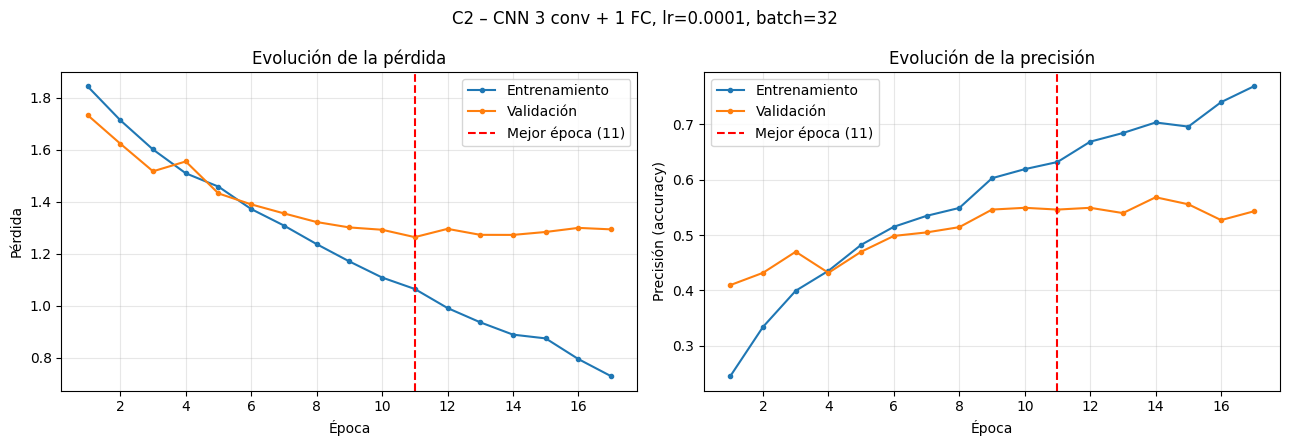

In [ ]:
C2 = {**C1, 'lr': 1e-4}
ejecutar_configuracion('C2', C2)

### C3 – Más *dropout*

Sobre C2, se sube el *dropout* de 0.25 a 0.5 para regularizar la capa densa, que concentra la mayoría de los parámetros (64·16·16·128 ≈ 2.1 M).

Parámetros entrenables: 2,163,495
Época [ 1/40] | Train Loss: 1.8664 | Train Acc: 0.2286 | Val Loss: 1.7656 | Val Acc: 0.3111  -> mejora
Época [ 2/40] | Train Loss: 1.7631 | Train Acc: 0.3014 | Val Loss: 1.6685 | Val Acc: 0.4095  -> mejora
Época [ 3/40] | Train Loss: 1.6527 | Train Acc: 0.3810 | Val Loss: 1.5517 | Val Acc: 0.4413  -> mejora
Época [ 4/40] | Train Loss: 1.5835 | Train Acc: 0.4109 | Val Loss: 1.5586 | Val Acc: 0.4413  -> sin mejora (1/6)
Época [ 5/40] | Train Loss: 1.5295 | Train Acc: 0.4605 | Val Loss: 1.4748 | Val Acc: 0.4730  -> mejora
Época [ 6/40] | Train Loss: 1.4895 | Train Acc: 0.4735 | Val Loss: 1.4171 | Val Acc: 0.5048  -> mejora
Época [ 7/40] | Train Loss: 1.4173 | Train Acc: 0.4973 | Val Loss: 1.3839 | Val Acc: 0.5111  -> mejora
Época [ 8/40] | Train Loss: 1.3784 | Train Acc: 0.4980 | Val Loss: 1.3708 | Val Acc: 0.5079  -> mejora
Época [ 9/40] | Train Loss: 1.3212 | Train Acc: 0.5442 | Val Loss: 1.3164 | Val Acc: 0.5238  -> mejora
Época [10/40] | Train Loss: 1

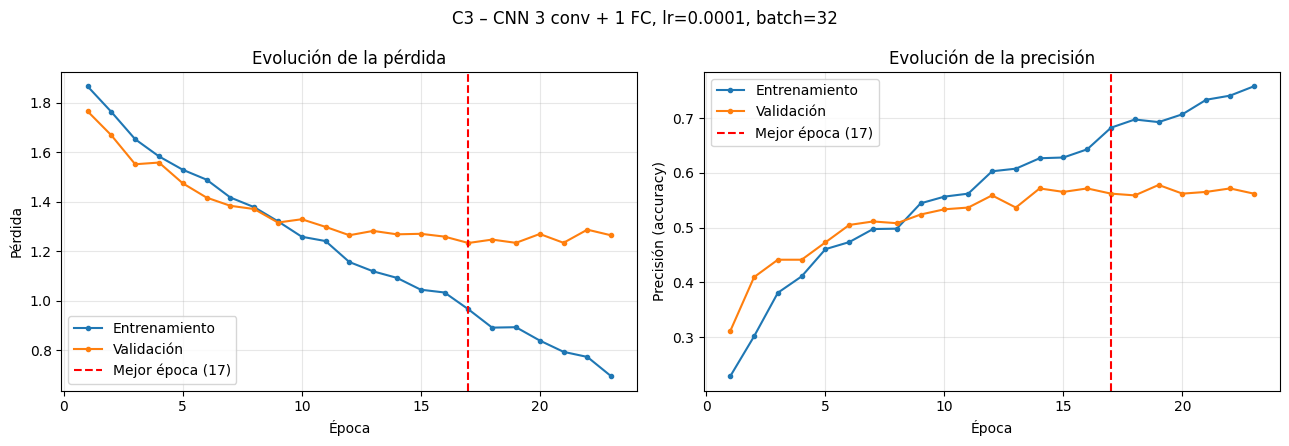

In [ ]:
C3 = {**C2, 'dropout': 0.5}
ejecutar_configuracion('C3', C3)

### C4 – Tamaño de lote mayor

Sobre C3, se pasa de lotes de 32 a 64 imágenes: gradientes menos ruidosos y menos actualizaciones por época.

Parámetros entrenables: 2,163,495
Época [ 1/40] | Train Loss: 1.8735 | Train Acc: 0.2293 | Val Loss: 1.7885 | Val Acc: 0.2603  -> mejora
Época [ 2/40] | Train Loss: 1.7981 | Train Acc: 0.2837 | Val Loss: 1.7350 | Val Acc: 0.3492  -> mejora
Época [ 3/40] | Train Loss: 1.7451 | Train Acc: 0.3245 | Val Loss: 1.6583 | Val Acc: 0.4222  -> mejora
Época [ 4/40] | Train Loss: 1.6672 | Train Acc: 0.3687 | Val Loss: 1.5885 | Val Acc: 0.4190  -> mejora
Época [ 5/40] | Train Loss: 1.6062 | Train Acc: 0.4238 | Val Loss: 1.5417 | Val Acc: 0.4444  -> mejora
Época [ 6/40] | Train Loss: 1.5545 | Train Acc: 0.4027 | Val Loss: 1.4969 | Val Acc: 0.4921  -> mejora
Época [ 7/40] | Train Loss: 1.5127 | Train Acc: 0.4558 | Val Loss: 1.4858 | Val Acc: 0.4730  -> mejora
Época [ 8/40] | Train Loss: 1.4883 | Train Acc: 0.4571 | Val Loss: 1.4578 | Val Acc: 0.5111  -> mejora
Época [ 9/40] | Train Loss: 1.4281 | Train Acc: 0.4878 | Val Loss: 1.3970 | Val Acc: 0.5143  -> mejora
Época [10/40] | Train Loss: 1.3961 | Tr

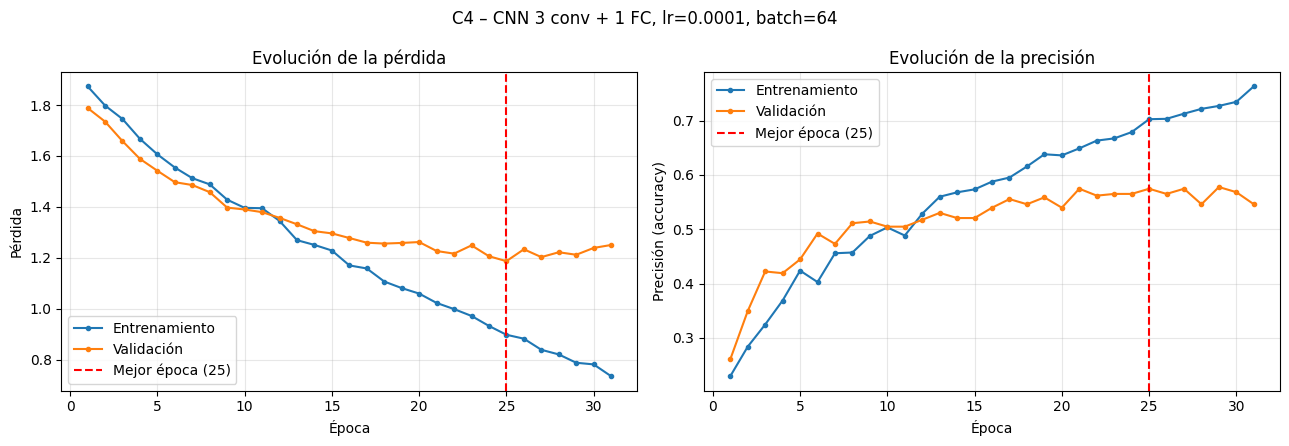

In [ ]:
C4 = {**C3, 'batch_size': 64}
ejecutar_configuracion('C4', C4)

### C5 – Más filtros por capa

Sobre C4, se duplica el número de filtros (32, 64 y 128) para aumentar la capacidad de extraer texturas y patrones de pincelada.

Parámetros entrenables: 4,453,959
Época [ 1/40] | Train Loss: 1.8828 | Train Acc: 0.2306 | Val Loss: 1.7397 | Val Acc: 0.3714  -> mejora
Época [ 2/40] | Train Loss: 1.7370 | Train Acc: 0.3327 | Val Loss: 1.6243 | Val Acc: 0.3937  -> mejora
Época [ 3/40] | Train Loss: 1.6496 | Train Acc: 0.3939 | Val Loss: 1.5591 | Val Acc: 0.4444  -> mejora
Época [ 4/40] | Train Loss: 1.5868 | Train Acc: 0.4048 | Val Loss: 1.5289 | Val Acc: 0.4508  -> mejora
Época [ 5/40] | Train Loss: 1.5192 | Train Acc: 0.4524 | Val Loss: 1.4700 | Val Acc: 0.4603  -> mejora
Época [ 6/40] | Train Loss: 1.4417 | Train Acc: 0.4803 | Val Loss: 1.4203 | Val Acc: 0.5016  -> mejora
Época [ 7/40] | Train Loss: 1.3965 | Train Acc: 0.4980 | Val Loss: 1.3750 | Val Acc: 0.5048  -> mejora
Época [ 8/40] | Train Loss: 1.3219 | Train Acc: 0.5272 | Val Loss: 1.3436 | Val Acc: 0.5111  -> mejora
Época [ 9/40] | Train Loss: 1.2550 | Train Acc: 0.5524 | Val Loss: 1.3094 | Val Acc: 0.5048  -> mejora
Época [10/40] | Train Loss: 1.2126 | Tr

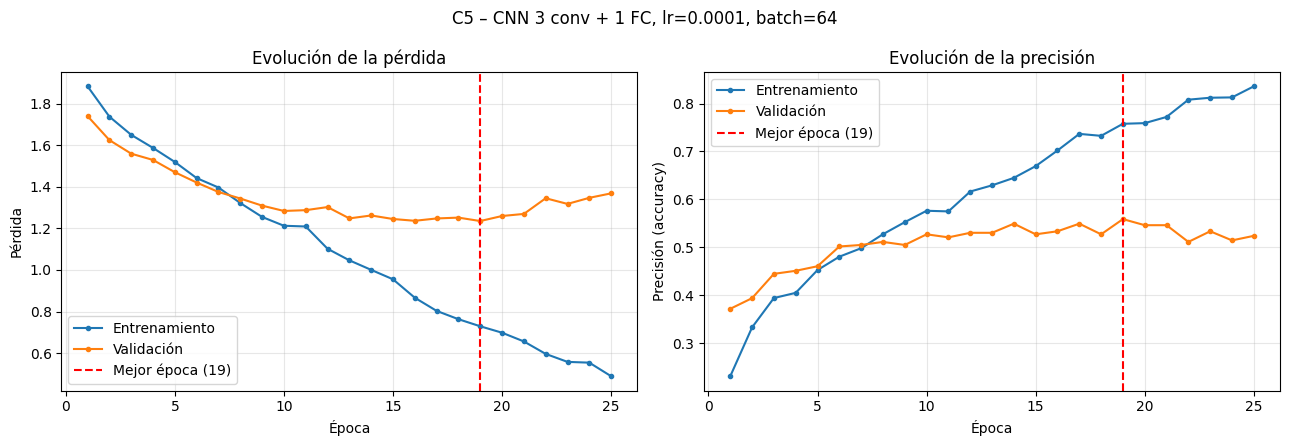

In [ ]:
C5 = {**C4, 'filtros': (32, 64, 128)}
ejecutar_configuracion('C5', C5)

### C6 – Red más profunda con *batch normalization*

Cambio de arquitectura: 4 capas convolucionales (32, 64, 128, 256) con kernels de 3×3 (dos 3×3 seguidos cubren el mismo campo receptivo que un 5×5 con menos parámetros) y *batch normalization* tras cada convolución. La capa densa pasa a 256 neuronas con *dropout* 0.5. Gracias a BatchNorm se vuelve a `lr = 0.001` y lotes de 32.

Parámetros entrenables: 4,585,735
Época [ 1/40] | Train Loss: 3.0430 | Train Acc: 0.1986 | Val Loss: 1.7102 | Val Acc: 0.3429  -> mejora
Época [ 2/40] | Train Loss: 1.7404 | Train Acc: 0.3075 | Val Loss: 1.5686 | Val Acc: 0.3873  -> mejora
Época [ 3/40] | Train Loss: 1.7251 | Train Acc: 0.3102 | Val Loss: 1.5362 | Val Acc: 0.4159  -> mejora
Época [ 4/40] | Train Loss: 1.6832 | Train Acc: 0.3354 | Val Loss: 1.5704 | Val Acc: 0.4000  -> sin mejora (1/6)
Época [ 5/40] | Train Loss: 1.6337 | Train Acc: 0.3626 | Val Loss: 1.6839 | Val Acc: 0.3302  -> sin mejora (2/6)
Época [ 6/40] | Train Loss: 1.5960 | Train Acc: 0.3925 | Val Loss: 1.5549 | Val Acc: 0.4159  -> sin mejora (3/6)
Época [ 7/40] | Train Loss: 1.5601 | Train Acc: 0.3980 | Val Loss: 1.3951 | Val Acc: 0.4794  -> mejora
Época [ 8/40] | Train Loss: 1.5144 | Train Acc: 0.4136 | Val Loss: 1.3360 | Val Acc: 0.4984  -> mejora
Época [ 9/40] | Train Loss: 1.4727 | Train Acc: 0.4259 | Val Loss: 1.4062 | Val Acc: 0.5048  -> sin mejora (1/6)

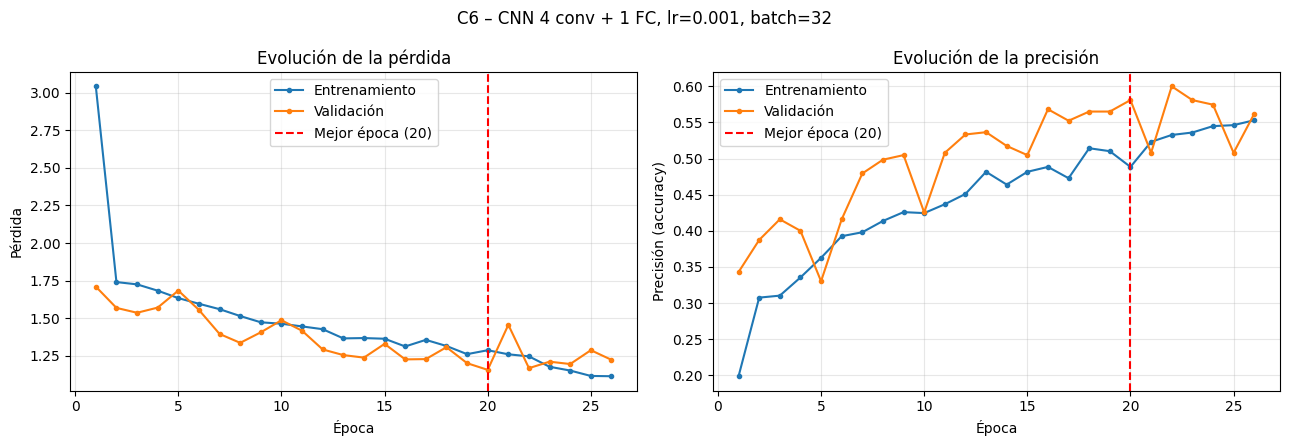

In [ ]:
C6 = {**C5, 'filtros': (32, 64, 128, 256), 'kernel': 3, 'batch_norm': True, 'neuronas': (256,),
      'lr': 1e-3, 'batch_size': 32}
ejecutar_configuracion('C6', C6)

### C7 – Dos capas completamente conectadas

Sobre C6, se añade una segunda capa densa (512 → 128 neuronas) para estudiar si un clasificador más profundo aprovecha mejor las características extraídas.

Parámetros entrenables: 8,845,063
Época [ 1/40] | Train Loss: 2.4552 | Train Acc: 0.1653 | Val Loss: 1.8992 | Val Acc: 0.2349  -> mejora
Época [ 2/40] | Train Loss: 1.9213 | Train Acc: 0.2190 | Val Loss: 1.8662 | Val Acc: 0.2222  -> mejora
Época [ 3/40] | Train Loss: 1.9080 | Train Acc: 0.2354 | Val Loss: 1.8067 | Val Acc: 0.2762  -> mejora
Época [ 4/40] | Train Loss: 1.8327 | Train Acc: 0.2701 | Val Loss: 1.7223 | Val Acc: 0.3492  -> mejora
Época [ 5/40] | Train Loss: 1.7937 | Train Acc: 0.3020 | Val Loss: 1.7819 | Val Acc: 0.3238  -> sin mejora (1/6)
Época [ 6/40] | Train Loss: 1.7309 | Train Acc: 0.3388 | Val Loss: 1.6196 | Val Acc: 0.4286  -> mejora
Época [ 7/40] | Train Loss: 1.6878 | Train Acc: 0.3762 | Val Loss: 1.6019 | Val Acc: 0.3778  -> mejora
Época [ 8/40] | Train Loss: 1.6599 | Train Acc: 0.3837 | Val Loss: 1.5176 | Val Acc: 0.4444  -> mejora
Época [ 9/40] | Train Loss: 1.6019 | Train Acc: 0.3980 | Val Loss: 1.5393 | Val Acc: 0.4476  -> sin mejora (1/6)
Época [10/40] | Tra

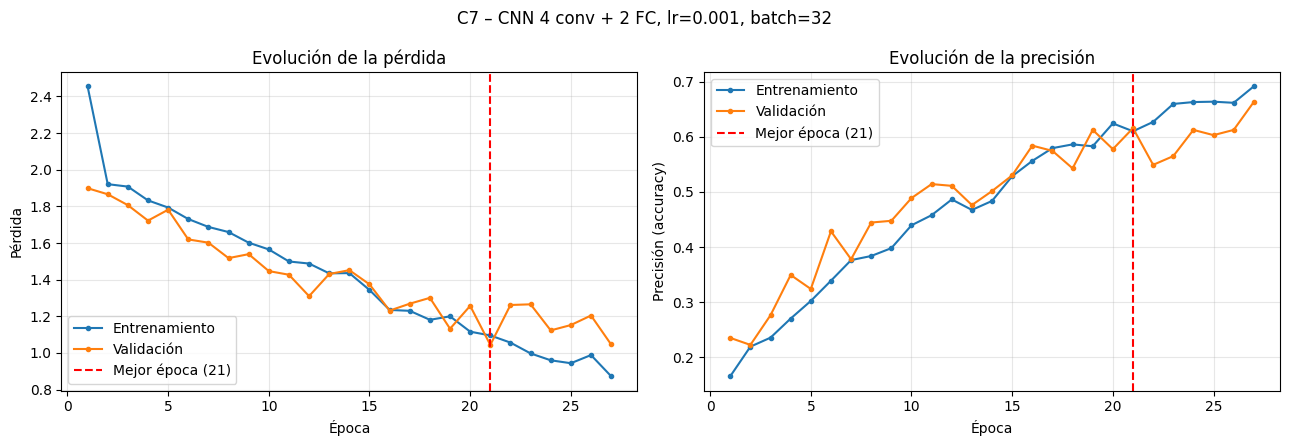

In [ ]:
C7 = {**C6, 'neuronas': (512, 128)}
ejecutar_configuracion('C7', C7)

### C8 – Función de activación LeakyReLU

Sobre C6, se sustituye ReLU por LeakyReLU (pendiente 0.1 para valores negativos), que evita neuronas "muertas" con gradiente nulo.

Parámetros entrenables: 4,585,735
Época [ 1/40] | Train Loss: 3.4239 | Train Acc: 0.2408 | Val Loss: 1.6278 | Val Acc: 0.3937  -> mejora
Época [ 2/40] | Train Loss: 1.8495 | Train Acc: 0.3639 | Val Loss: 1.5743 | Val Acc: 0.4190  -> mejora
Época [ 3/40] | Train Loss: 1.7031 | Train Acc: 0.4116 | Val Loss: 1.4067 | Val Acc: 0.4698  -> mejora
Época [ 4/40] | Train Loss: 1.6123 | Train Acc: 0.4544 | Val Loss: 1.5838 | Val Acc: 0.4349  -> sin mejora (1/6)
Época [ 5/40] | Train Loss: 1.4557 | Train Acc: 0.4939 | Val Loss: 1.8664 | Val Acc: 0.3841  -> sin mejora (2/6)
Época [ 6/40] | Train Loss: 1.3502 | Train Acc: 0.5245 | Val Loss: 1.3608 | Val Acc: 0.5143  -> mejora
Época [ 7/40] | Train Loss: 1.2815 | Train Acc: 0.5395 | Val Loss: 1.2503 | Val Acc: 0.5175  -> mejora
Época [ 8/40] | Train Loss: 1.2605 | Train Acc: 0.5599 | Val Loss: 1.2141 | Val Acc: 0.6063  -> mejora
Época [ 9/40] | Train Loss: 1.1301 | Train Acc: 0.5905 | Val Loss: 1.1668 | Val Acc: 0.6095  -> mejora
Época [10/40] | Tra

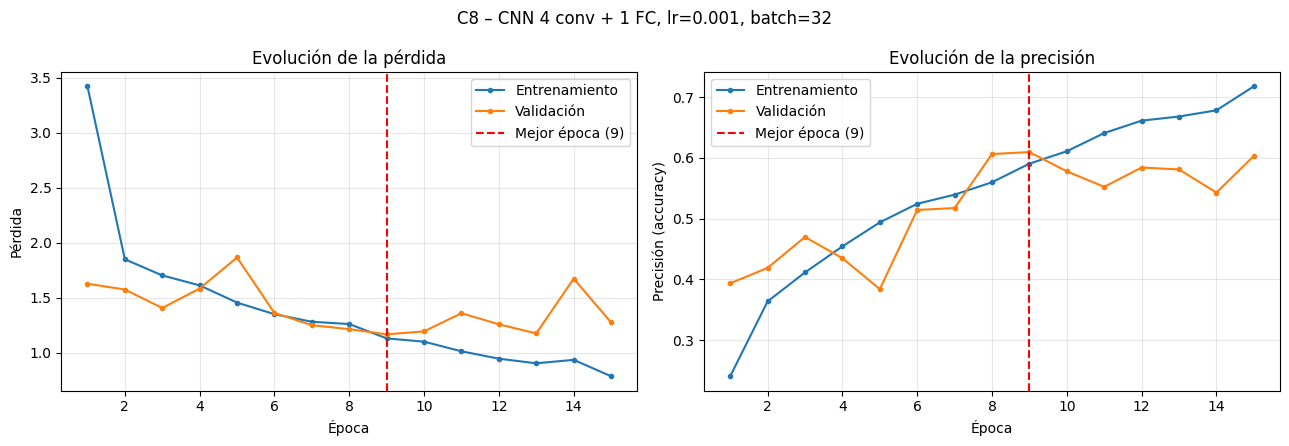

In [ ]:
C8 = {**C6, 'activacion': 'leaky_relu'}
ejecutar_configuracion('C8', C8)

### C9 – *Global average pooling*

Sobre C6, se sustituye el aplanado del mapa final (256·8·8 = 16 384 entradas a la capa densa) por la media global de cada mapa (256 entradas). Los parámetros totales bajan de unos 4.6 M a unos 0.5 M, lo que debería reducir el sobreajuste.

Parámetros entrenables: 456,967
Época [ 1/40] | Train Loss: 1.6409 | Train Acc: 0.3721 | Val Loss: 1.6770 | Val Acc: 0.3524  -> mejora
Época [ 2/40] | Train Loss: 1.4701 | Train Acc: 0.4653 | Val Loss: 1.4153 | Val Acc: 0.4444  -> mejora
Época [ 3/40] | Train Loss: 1.3433 | Train Acc: 0.4959 | Val Loss: 1.2324 | Val Acc: 0.5556  -> mejora
Época [ 4/40] | Train Loss: 1.2337 | Train Acc: 0.5510 | Val Loss: 1.1271 | Val Acc: 0.5556  -> mejora
Época [ 5/40] | Train Loss: 1.2070 | Train Acc: 0.5673 | Val Loss: 1.5251 | Val Acc: 0.5175  -> sin mejora (1/6)
Época [ 6/40] | Train Loss: 1.1326 | Train Acc: 0.5850 | Val Loss: 1.1286 | Val Acc: 0.5937  -> sin mejora (2/6)
Época [ 7/40] | Train Loss: 1.1194 | Train Acc: 0.5884 | Val Loss: 1.2701 | Val Acc: 0.5492  -> sin mejora (3/6)
Época [ 8/40] | Train Loss: 1.1030 | Train Acc: 0.6088 | Val Loss: 1.1066 | Val Acc: 0.5683  -> mejora
Época [ 9/40] | Train Loss: 1.0395 | Train Acc: 0.6150 | Val Loss: 1.3352 | Val Acc: 0.5270  -> sin mejora (1/6)
É

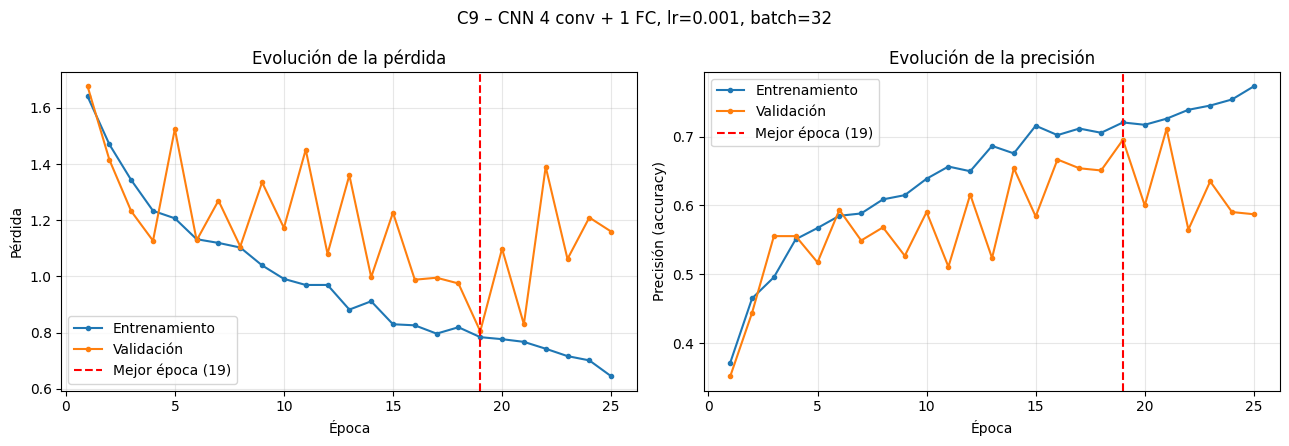

In [ ]:
C9 = {**C6, 'pooling_global': True}
ejecutar_configuracion('C9', C9)

### C10 – Aumento de datos (opcional)

Sobre C9, se activa el aumento de datos en entrenamiento. Como cada época ve versiones distintas de las imágenes, la red tarda más en converger: se amplía el máximo a 60 épocas, la paciencia a 10 y se reduce la tasa de aprendizaje a la mitad cuando la validación se estanca.

Parámetros entrenables: 456,967
Época [ 1/60] | Train Loss: 1.6897 | Train Acc: 0.3442 | Val Loss: 1.9104 | Val Acc: 0.2698  -> mejora
Época [ 2/60] | Train Loss: 1.5549 | Train Acc: 0.4218 | Val Loss: 1.6560 | Val Acc: 0.3365  -> mejora
Época [ 3/60] | Train Loss: 1.4420 | Train Acc: 0.4776 | Val Loss: 1.3724 | Val Acc: 0.5048  -> mejora
Época [ 4/60] | Train Loss: 1.3263 | Train Acc: 0.5136 | Val Loss: 1.3258 | Val Acc: 0.5079  -> mejora
Época [ 5/60] | Train Loss: 1.3279 | Train Acc: 0.5156 | Val Loss: 1.2657 | Val Acc: 0.5175  -> mejora
Época [ 6/60] | Train Loss: 1.2083 | Train Acc: 0.5701 | Val Loss: 1.2568 | Val Acc: 0.5365  -> mejora
Época [ 7/60] | Train Loss: 1.2439 | Train Acc: 0.5503 | Val Loss: 1.4220 | Val Acc: 0.5111  -> sin mejora (1/10)
Época [ 8/60] | Train Loss: 1.2161 | Train Acc: 0.5680 | Val Loss: 1.2052 | Val Acc: 0.5206  -> mejora
Época [ 9/60] | Train Loss: 1.1799 | Train Acc: 0.5707 | Val Loss: 1.1936 | Val Acc: 0.5778  -> mejora
Época [10/60] | Train Loss: 1.

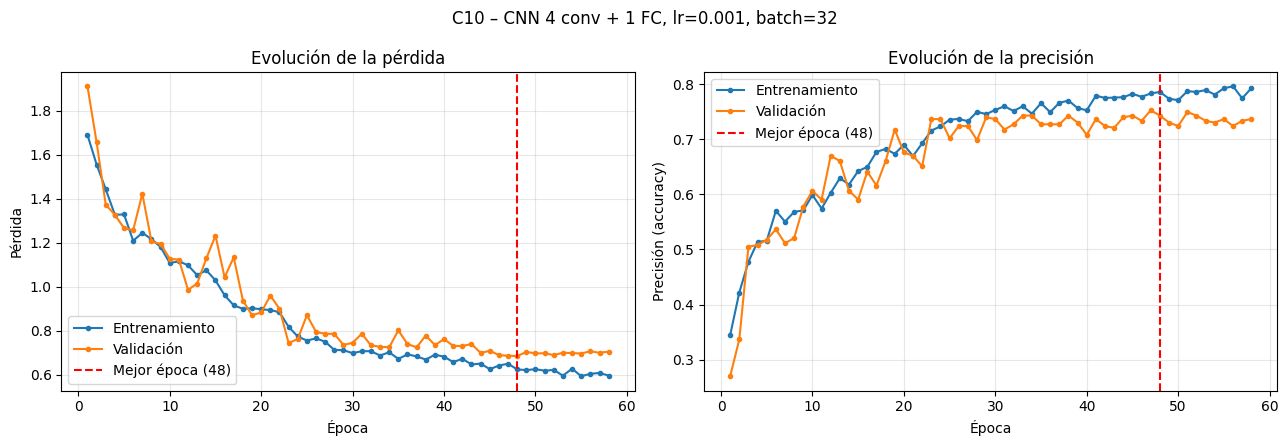

In [ ]:
C10 = {**C9, 'aumento': True, 'scheduler': True, 'epocas': 60, 'paciencia': 10}
ejecutar_configuracion('C10', C10)

### Resultados de la búsqueda manual

In [ ]:
COLUMNAS_RESUMEN = ['Arquitectura', 'Filtros', 'Kernel', 'Neuronas FC', 'Activación', 'Dropout', 'BatchNorm', 'GAP',
                    'Aumento', 'LR', 'Batch', 'Épocas entrenadas', 'Mejor época',
                    'Pérdida val', 'Acc train (%)', 'Acc val (%)', 'Tiempo (s)']

pd.DataFrame([r for r in resultados if r['Tipo'] == 'Manual']).set_index('Configuración')[COLUMNAS_RESUMEN]

,Arquitectura,Filtros,Kernel,Neuronas FC,Activación,Dropout,BatchNorm,GAP,Aumento,LR,Batch,Épocas entrenadas,Mejor época,Pérdida val,Acc train (%),Acc val (%),Tiempo (s)
Configuración,,,,,,,,,,,,,,,,,
C1,CNN 3 conv + 1 FC,16-32-64,5,128,relu,0.25,False,False,False,0.0010,32,12,6,1.3742,58.44,47.94,46.4
C2,CNN 3 conv + 1 FC,16-32-64,5,128,relu,0.25,False,False,False,0.0001,32,17,11,1.2639,63.20,54.60,62.3
C3,CNN 3 conv + 1 FC,16-32-64,5,128,relu,0.50,False,False,False,0.0001,32,23,17,1.2337,68.23,56.19,84.4
C4,CNN 3 conv + 1 FC,16-32-64,5,128,relu,0.50,False,False,False,0.0001,64,31,25,1.1868,70.27,57.46,114.2
C5,CNN 3 conv + 1 FC,32-64-128,5,128,relu,0.50,False,False,False,0.0001,64,25,19,1.2353,75.78,55.87,94.2
C6,CNN 4 conv + 1 FC,32-64-128-256,3,256,relu,0.50,True,False,False,0.0010,32,26,20,1.1563,48.84,58.10,97.0
C7,CNN 4 conv + 2 FC,32-64-128-256,3,512-128,relu,0.50,True,False,False,0.0010,32,27,21,1.0438,61.02,61.59,101.8
C8,CNN 4 conv + 1 FC,32-64-128-256,3,256,leaky_relu,0.50,True,False,False,0.0010,32,15,9,1.1668,59.05,60.95,55.7
C9,CNN 4 conv + 1 FC,32-64-128-256,3,256,relu,0.50,True,True,False,0.0010,32,25,19,0.8047,72.04,69.52,91.9


## 6. *Transfer learning* con ResNet-50

Se utiliza **ResNet-50**, preentrenada en ImageNet, para aprovechar las características visuales aprendidas y adaptarlas a la clasificación de estilos artísticos.

El entrenamiento se divide en dos fases, ambas con parada anticipada:

1. **Extracción de características:** se congelan las capas preentrenadas y solo se entrena la nueva capa de salida de 7 clases (`lr = 0.001`).
2. **Ajuste fino (*fine-tuning*):** se descongela toda la red y se entrena con una tasa de aprendizaje menor (`lr = 0.0001`), utilizando reducción en meseta.

Se emplean imágenes de **224×224** y aumento de datos. Se conservan los mejores pesos según la pérdida de validación.

In [ ]:
CFG_TL = dict(batch_size=32, aumento=True,
              lr_cabeza=1e-3, epocas_cabeza=10, paciencia_cabeza=3,
              lr_ajuste=1e-4, epocas_ajuste=25, paciencia_ajuste=5)


def crear_preentrenado():
    modelo = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    for parametro in modelo.parameters():
        parametro.requires_grad = False
    modelo.fc = nn.Linear(modelo.fc.in_features, num_clases)
    return modelo


def ejecutar_transfer_learning(nombre='ResNet-50', cfg=CFG_TL):
    fijar_semilla()
    loader_train, loader_val, _ = crear_loaders(cfg['batch_size'], TAM_PREENTRENADO, cfg['aumento'])
    modelo = crear_preentrenado().to(device)
    inicio = time()

    print(f'--- {nombre} | Fase 1: solo la capa de salida '
          f'({contar_parametros(modelo):,} de {contar_parametros(modelo, False):,} parámetros entrenables)')
    hist_cabeza = entrenar(modelo, loader_train, loader_val, lr=cfg['lr_cabeza'], epocas=cfg['epocas_cabeza'],
                           paciencia=cfg['paciencia_cabeza'])
    estado_cabeza = copy.deepcopy(modelo.state_dict())

    for parametro in modelo.parameters():
        parametro.requires_grad = True
    print(f'--- {nombre} | Fase 2: ajuste fino de toda la red ({contar_parametros(modelo):,} parámetros entrenables)')
    hist_ajuste = entrenar(modelo, loader_train, loader_val, lr=cfg['lr_ajuste'], epocas=cfg['epocas_ajuste'],
                           paciencia=cfg['paciencia_ajuste'], scheduler=True)
    duracion = time() - inicio

    epocas_cabeza = len(hist_cabeza['perdida_train'])
    historial = {clave: hist_cabeza[clave] + hist_ajuste[clave]
                 for clave in ('perdida_train', 'perdida_val', 'acc_train', 'acc_val')}
    if min(hist_cabeza['perdida_val']) <= min(hist_ajuste['perdida_val']):
        modelo.load_state_dict(estado_cabeza)
        historial['mejor_epoca'] = hist_cabeza['mejor_epoca']
    else:
        historial['mejor_epoca'] = epocas_cabeza + hist_ajuste['mejor_epoca']
    historial['separaciones'] = [epocas_cabeza]

    parametros = {
        'Arquitectura': f'{nombre} (ImageNet)',
        'Aumento': cfg['aumento'],
        'LR': f"{cfg['lr_cabeza']} / {cfg['lr_ajuste']}",
        'Batch': cfg['batch_size'],
        'Épocas máx.': f"{cfg['epocas_cabeza']} + {cfg['epocas_ajuste']}",
        'Paciencia': f"{cfg['paciencia_cabeza']} / {cfg['paciencia_ajuste']}"
    }
    registrar(nombre, 'Transfer learning', parametros, modelo, historial, TAM_PREENTRENADO, cfg['batch_size'], duracion)
    graficar_historial(historial, f'{nombre} – transfer learning (extracción de características + ajuste fino)')

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 171MB/s]


--- ResNet-50 | Fase 1: solo la capa de salida (14,343 de 23,522,375 parámetros entrenables)
Época [ 1/10] | Train Loss: 1.3664 | Train Acc: 0.6361 | Val Loss: 0.9922 | Val Acc: 0.7714  -> mejora
Época [ 2/10] | Train Loss: 0.8363 | Train Acc: 0.7803 | Val Loss: 0.7718 | Val Acc: 0.8127  -> mejora
Época [ 3/10] | Train Loss: 0.6808 | Train Acc: 0.8170 | Val Loss: 0.6523 | Val Acc: 0.8317  -> mejora
Época [ 4/10] | Train Loss: 0.5499 | Train Acc: 0.8490 | Val Loss: 0.5851 | Val Acc: 0.8413  -> mejora
Época [ 5/10] | Train Loss: 0.5080 | Train Acc: 0.8660 | Val Loss: 0.5548 | Val Acc: 0.8381  -> mejora
Época [ 6/10] | Train Loss: 0.4314 | Train Acc: 0.8884 | Val Loss: 0.5135 | Val Acc: 0.8571  -> mejora
Época [ 7/10] | Train Loss: 0.3993 | Train Acc: 0.8918 | Val Loss: 0.5138 | Val Acc: 0.8540  -> sin mejora (1/3)
Época [ 8/10] | Train Loss: 0.3805 | Train Acc: 0.8973 | Val Loss: 0.4946 | Val Acc: 0.8508  -> mejora
Época [ 9/10] | Train Loss: 0.3463 | Train Acc: 0.9075 | Val Loss: 0.4554

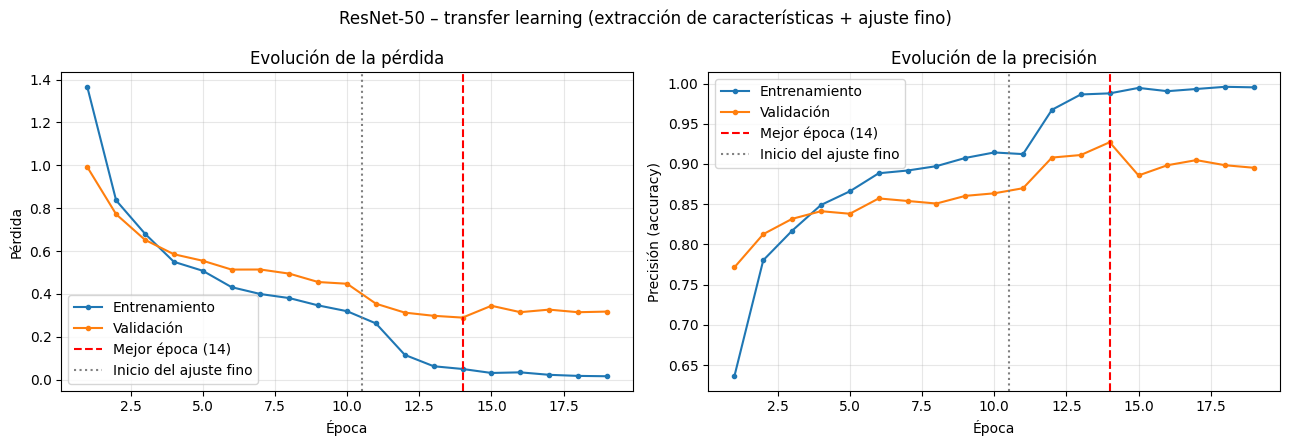

In [ ]:
ejecutar_transfer_learning('ResNet-50')

## 7. Comparativa de todas las configuraciones

Tabla completa de las pruebas realizadas (búsqueda manual y *transfer learning*) y comparación de la precisión de validación. La tabla también se guarda como CSV en la carpeta del proyecto.

In [ ]:
tabla_resultados = pd.DataFrame(resultados).set_index('Configuración')
tabla_resultados.to_csv(os.path.join(raiz_AA2, 'resultados_configuraciones.csv'))
tabla_resultados.fillna('—')

,Tipo,Arquitectura,Filtros,Kernel,Neuronas FC,Activación,Dropout,BatchNorm,GAP,Aumento,LR,Batch,Épocas máx.,Paciencia,Épocas entrenadas,Mejor época,Pérdida val,Acc train (%),Acc val (%),Tiempo (s)
Configuración,,,,,,,,,,,,,,,,,,,,
C1,Manual,CNN 3 conv + 1 FC,16-32-64,5.0,128,relu,0.25,False,False,False,0.001,32,40,6,12,6,1.3742,58.44,47.94,46.4
C2,Manual,CNN 3 conv + 1 FC,16-32-64,5.0,128,relu,0.25,False,False,False,0.0001,32,40,6,17,11,1.2639,63.20,54.60,62.3
C3,Manual,CNN 3 conv + 1 FC,16-32-64,5.0,128,relu,0.5,False,False,False,0.0001,32,40,6,23,17,1.2337,68.23,56.19,84.4
C4,Manual,CNN 3 conv + 1 FC,16-32-64,5.0,128,relu,0.5,False,False,False,0.0001,64,40,6,31,25,1.1868,70.27,57.46,114.2
C5,Manual,CNN 3 conv + 1 FC,32-64-128,5.0,128,relu,0.5,False,False,False,0.0001,64,40,6,25,19,1.2353,75.78,55.87,94.2
C6,Manual,CNN 4 conv + 1 FC,32-64-128-256,3.0,256,relu,0.5,True,False,False,0.001,32,40,6,26,20,1.1563,48.84,58.10,97.0
C7,Manual,CNN 4 conv + 2 FC,32-64-128-256,3.0,512-128,relu,0.5,True,False,False,0.001,32,40,6,27,21,1.0438,61.02,61.59,101.8
C8,Manual,CNN 4 conv + 1 FC,32-64-128-256,3.0,256,leaky_relu,0.5,True,False,False,0.001,32,40,6,15,9,1.1668,59.05,60.95,55.7
C9,Manual,CNN 4 conv + 1 FC,32-64-128-256,3.0,256,relu,0.5,True,True,False,0.001,32,40,6,25,19,0.8047,72.04,69.52,91.9


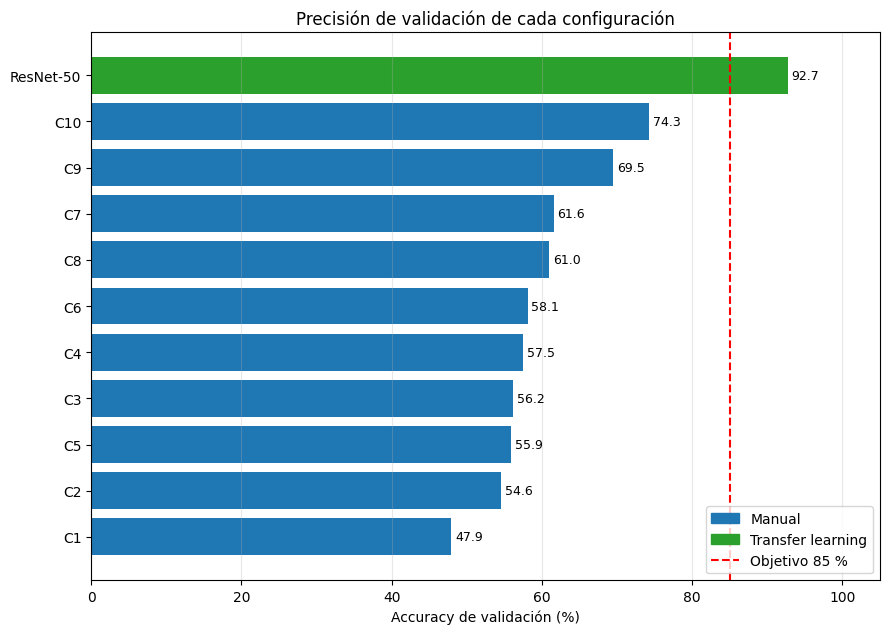

In [ ]:
COLORES_TIPO = {'Manual': 'tab:blue', 'Transfer learning': 'tab:green'}

orden = pd.DataFrame(resultados).sort_values('Acc val (%)')
plt.figure(figsize=(9, 0.45 * len(orden) + 1.5))
plt.barh(orden['Configuración'], orden['Acc val (%)'], color=orden['Tipo'].map(COLORES_TIPO))
for posicion, valor in enumerate(orden['Acc val (%)']):
    plt.text(valor + 0.5, posicion, f'{valor:.1f}', va='center', fontsize=9)
plt.axvline(85, color='red', linestyle='--')
plt.legend(handles=[Patch(color=c, label=t) for t, c in COLORES_TIPO.items()]
           + [plt.Line2D([], [], color='red', linestyle='--', label='Objetivo 85 %')], loc='lower right')
plt.xlabel('Accuracy de validación (%)')
plt.xlim(0, 105)
plt.title('Precisión de validación de cada configuración')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

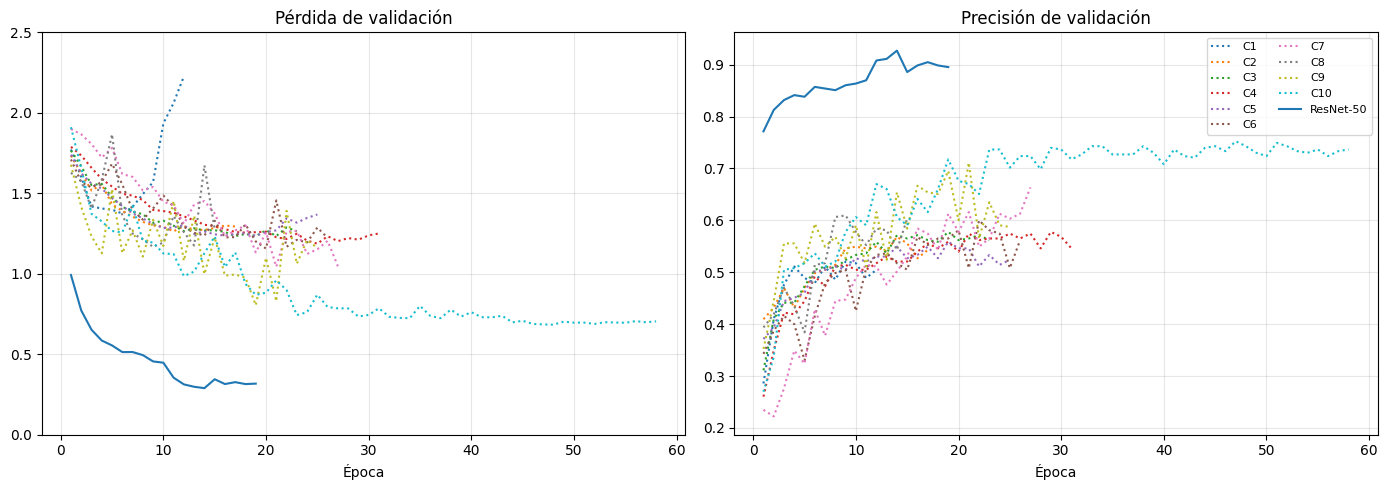

In [ ]:
_, ejes = plt.subplots(1, 2, figsize=(14, 5))
for nombre, info in modelos.items():
    estilo = '-' if info['tam'] == TAM_PREENTRENADO else ':'
    ejes[0].plot(range(1, len(info['historial']['perdida_val']) + 1), info['historial']['perdida_val'], estilo, label=nombre)
    ejes[1].plot(range(1, len(info['historial']['acc_val']) + 1), info['historial']['acc_val'], estilo, label=nombre)
for eje, titulo in zip(ejes, ['Pérdida de validación', 'Precisión de validación']):
    eje.set_title(titulo)
    eje.set_xlabel('Época')
    eje.grid(True, alpha=0.3)
ejes[0].set_ylim(0, 2.5)
ejes[1].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

## 8. Evaluación final en test

Se evalúan los dos modelos seleccionados según su rendimiento en validación:

- **C10:** mejor CNN entrenada desde cero.
- **ResNet-50:** mejor modelo global mediante *transfer learning*.

Para ambos se muestran el **informe de clasificación por clase** y las **matrices de confusión**, tanto en valores absolutos como normalizados.

In [ ]:
def evaluar_en_test(nombre):
    info = modelos[nombre]
    modelo = info['modelo'].to(device)
    _, _, loader_test = crear_loaders(info['batch_size'], info['tam'])
    perdida, acc, y_real, y_pred = evaluar(modelo, loader_test)
    modelo.cpu()

    print(f'=== {nombre} | Test: pérdida {perdida:.4f} | accuracy {100 * acc:.2f}% ===\n')
    print(classification_report(y_real, y_pred, target_names=clases, digits=3))

    _, ejes = plt.subplots(1, 2, figsize=(15, 6))
    ConfusionMatrixDisplay.from_predictions(y_real, y_pred, display_labels=clases, cmap='Blues',
                                            xticks_rotation=45, colorbar=False, ax=ejes[0])
    ConfusionMatrixDisplay.from_predictions(y_real, y_pred, display_labels=clases, cmap='Blues', normalize='true',
                                            values_format='.2f', xticks_rotation=45, colorbar=False, ax=ejes[1])
    ejes[0].set_title('Valores absolutos')
    ejes[1].set_title('Normalizada por clase real')
    plt.suptitle(f'Matriz de confusión en test – {nombre} (accuracy {100 * acc:.2f}%)')
    plt.tight_layout()
    plt.show()
    return {'Modelo': nombre, 'Pérdida test': round(perdida, 4), 'Acc test (%)': round(100 * acc, 2)}, y_real, y_pred


mejor_propia = max((r for r in resultados if r['Tipo'] != 'Transfer learning'), key=lambda r: r['Acc val (%)'])['Configuración']
mejor_global = max(resultados, key=lambda r: r['Acc val (%)'])['Configuración']
print(f'Mejor CNN propia (validación): {mejor_propia}')
print(f'Mejor modelo global (validación): {mejor_global}')

Mejor CNN propia (validación): C10
Mejor modelo global (validación): ResNet-50


### 8.1 Mejor CNN entrenada desde cero

=== C10 | Test: pérdida 0.7425 | accuracy 74.60% ===

               precision    recall  f1-score   support

      Baroque      0.717     0.844     0.776        45
       Cubism      0.722     0.578     0.642        45
Impressionism      0.660     0.689     0.674        45
     Medieval      0.690     0.644     0.667        45
   Minimalism      0.857     0.800     0.828        45
  Pointillism      0.787     0.822     0.804        45
        Ukiyo      0.792     0.844     0.817        45

     accuracy                          0.746       315
    macro avg      0.746     0.746     0.744       315
 weighted avg      0.746     0.746     0.744       315



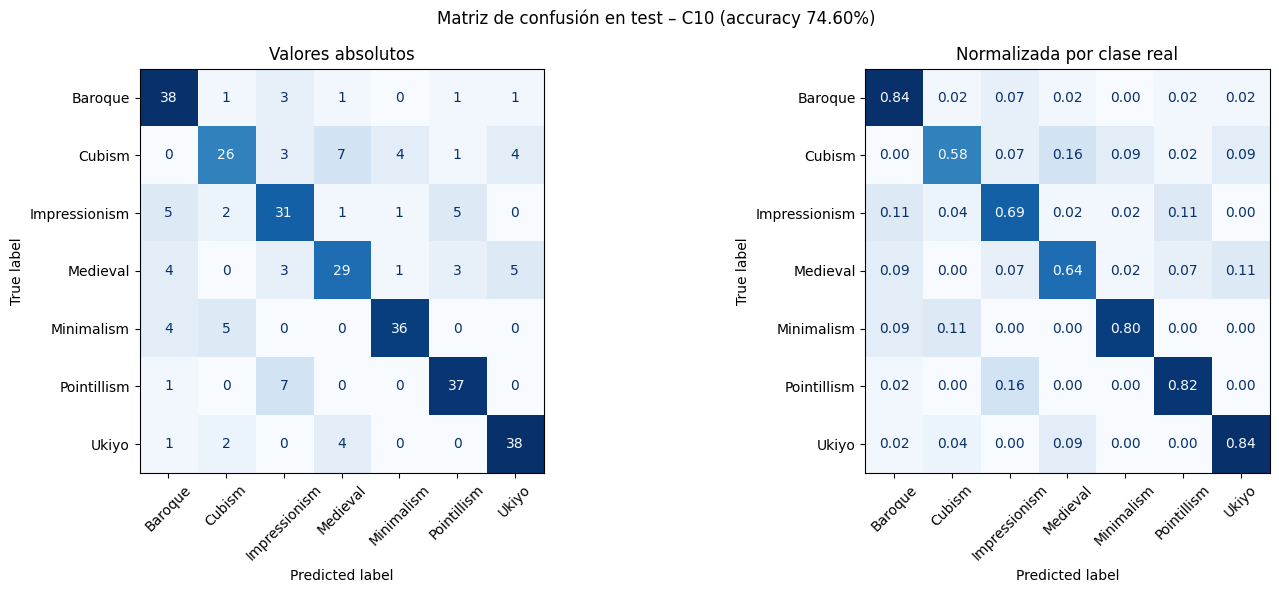

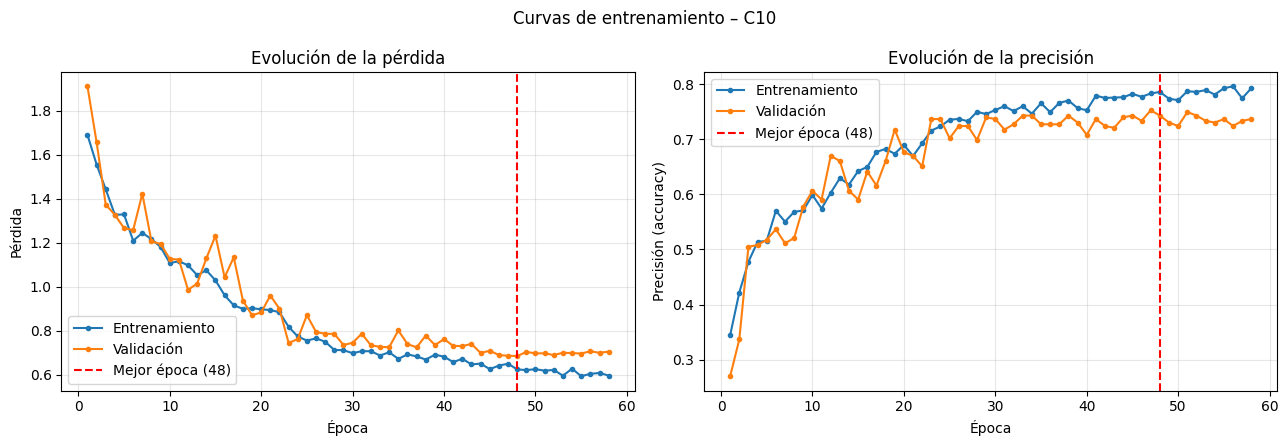

In [ ]:
resultado_propia, _, _ = evaluar_en_test(mejor_propia)
graficar_historial(modelos[mejor_propia]['historial'], f'Curvas de entrenamiento – {mejor_propia}')

### 8.2 Mejor modelo global

=== ResNet-50 | Test: pérdida 0.4683 | accuracy 87.62% ===

               precision    recall  f1-score   support

      Baroque      0.824     0.933     0.875        45
       Cubism      0.923     0.800     0.857        45
Impressionism      0.833     0.667     0.741        45
     Medieval      0.808     0.933     0.866        45
   Minimalism      1.000     0.956     0.977        45
  Pointillism      0.864     0.844     0.854        45
        Ukiyo      0.900     1.000     0.947        45

     accuracy                          0.876       315
    macro avg      0.879     0.876     0.874       315
 weighted avg      0.879     0.876     0.874       315



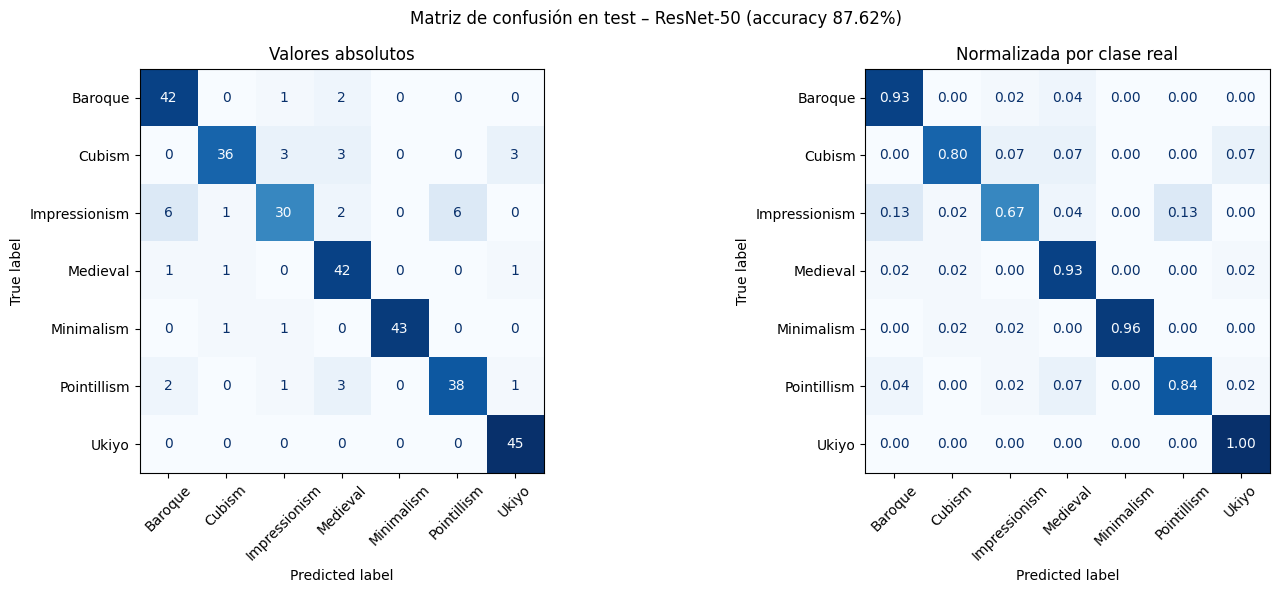

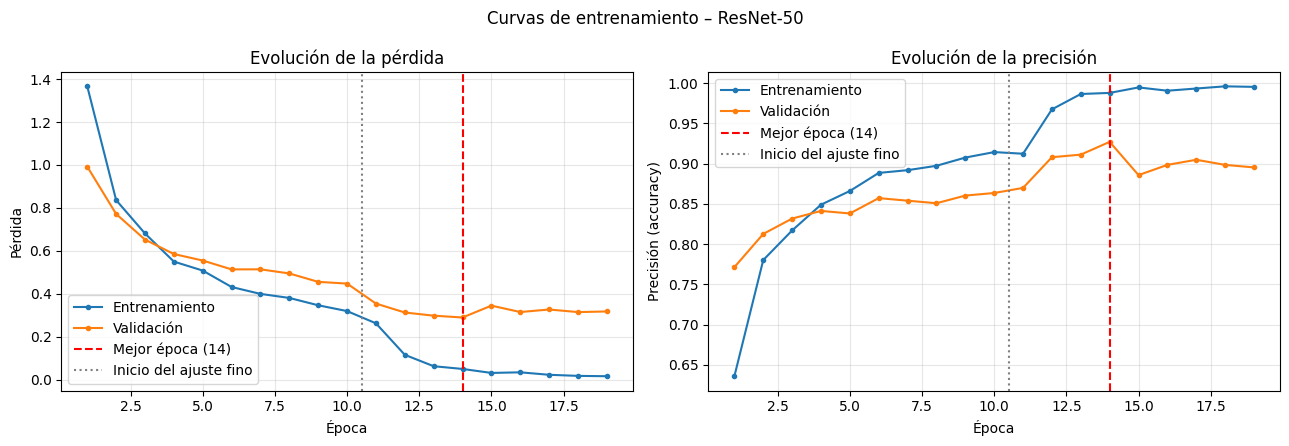

In [ ]:
resultado_global, y_real_test, y_pred_test = evaluar_en_test(mejor_global)
graficar_historial(modelos[mejor_global]['historial'], f'Curvas de entrenamiento – {mejor_global}')

Algunas imágenes de test mal clasificadas por el mejor modelo, útiles para analizar qué estilos se confunden y por qué:

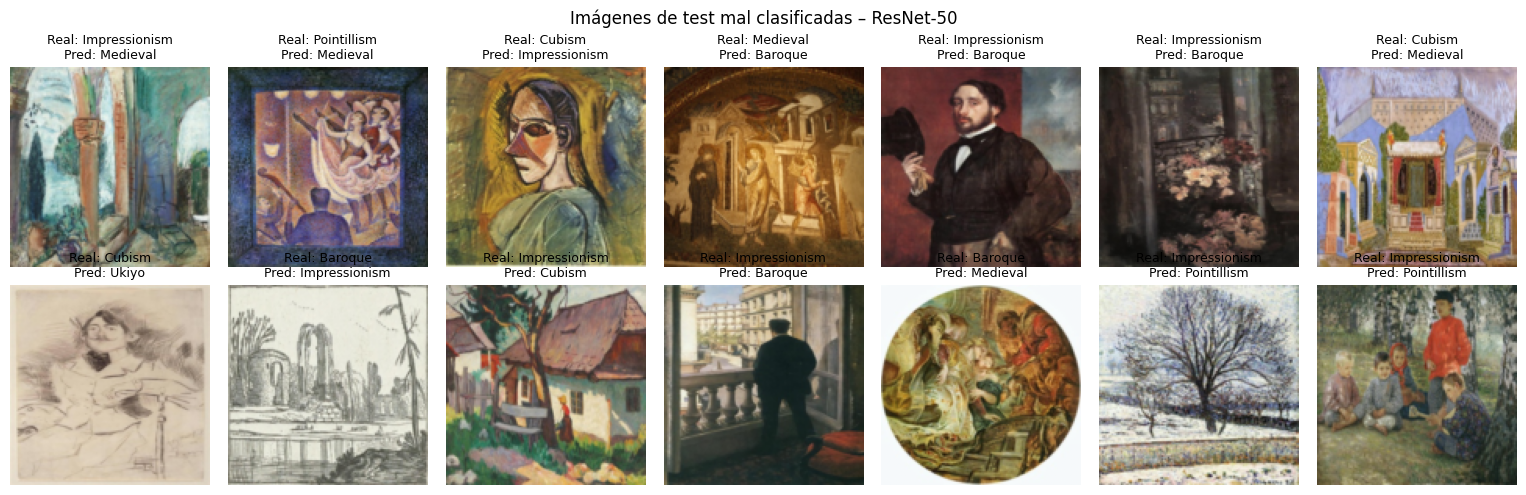

In [ ]:
errores = np.where(y_real_test != y_pred_test)[0][:14]
if len(errores):
    mostrar_imagenes([dataset_visual[indices_test[i]][0] for i in errores],
                     [f'Real: {clases[y_real_test[i]]}\nPred: {clases[y_pred_test[i]]}' for i in errores],
                     f'Imágenes de test mal clasificadas – {mejor_global}')
else:
    print('No hay errores en test')

In [ ]:
torch.save(modelos[mejor_global]['modelo'].state_dict(), os.path.join(raiz_AA2, 'mejor_modelo.pt'))
pd.DataFrame([resultado_propia, resultado_global]).drop_duplicates('Modelo').set_index('Modelo')

,Pérdida test,Acc test (%)
Modelo,,
C10,0.7425,74.60
ResNet-50,0.4683,87.62


In [ ]:
tabla = pd.DataFrame(resultados)
for tipo in ['Manual', 'Transfer learning']:
    subtabla = tabla[tabla['Tipo'] == tipo]
    if len(subtabla):
        mejor = subtabla.loc[subtabla['Acc val (%)'].idxmax()]
        print(f'{tipo:18s}: mejor = {mejor["Configuración"]:16s} acc val = {mejor["Acc val (%)"]:.2f}% '
              f'(peor = {subtabla["Acc val (%)"].min():.2f}%, {len(subtabla)} configuraciones)')
print()
for resultado in [resultado_propia, resultado_global]:
    print(f'Test {resultado["Modelo"]:16s}: accuracy = {resultado["Acc test (%)"]:.2f}%')

Manual            : mejor = C10              acc val = 74.29% (peor = 47.94%, 10 configuraciones)
Transfer learning : mejor = ResNet-50        acc val = 92.70% (peor = 92.70%, 1 configuraciones)

Test C10             : accuracy = 74.60%
Test ResNet-50       : accuracy = 87.62%


### Resultados finales

La mejor CNN propia (C10) obtuvo un **74,60 % de accuracy en test**, mientras que ResNet-50 alcanzó un **87,62 %**, superando el objetivo del 85 %.

El análisis detallado de los experimentos y las conclusiones se encuentran en la memoria.